### 05B · Modelo de ruido conjunto Hs–Tm02: TVAR bivariado + mapeo por decil de f_Hs × mes
r = Z − f para Hs (04) y para Tm02 (04B), con f fuera de muestra (OOF 1985–2015, modelo final 2016–2025). Mismo esquema que el 05, con dos columnas:
- **Dinámica (TVAR):** VAR(20) bivariado distinto en calma (f_Hs < q90) y en temporal (f_Hs ≥ q90), retardos de la serie entera (incluye retardos cruzados: el residuo del periodo va ~3 h por detrás del de Hs).
- **Innovaciones:** pares reales (e_Hs, e_Tm) sorteados por decil de f_Hs: la correlación de los choques sube de 0,05 (calma) a 0,49 (temporal) y la σ de los de Tm se reduce a la mitad.
- **Marginal (mapeo por rangos):** cada variable por separado, en la clase decil de f_Hs × mes (la dispersión de r_Tm depende más de f_Hs que de f_Tm), con los residuos reales de esa clase. Conserva los rangos, y con ellos la dependencia que da el TVAR.
- **Hindcast:** f histórica 1985–2025 + 50 realizaciones → Hs y Tm02, frente al observado.

Salidas: `outputs/ruido/ruido_tar_hstm_{point}.pkl` y `outputs/ruido/olas_hindcast_{point}.pkl`. No toca las del 05 (Hs sola, producción).

In [43]:
import os, time, pickle

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from scipy.signal import find_peaks
from scipy.stats import genextreme, skew

from utils.tv_var.periodic_var import PeriodicVAR, select_order
from utils.pit.piece_wise_marginal import from_normal

#### Datos

In [44]:
point = 'p102'
HINDCAST = ('1985', '2025')                    # periodo del hindcast completo
TEST = ('2016', '2025')                        # periodo fuera de muestra para el XGB y para los pools

resid_hs = pd.read_csv(f"outputs/xgb_{point}/residuos_horarios.csv", index_col=0, parse_dates=True)
resid_tm = pd.read_csv(f"outputs/xgb_{point}_tm/residuos_horarios.csv", index_col=0, parse_dates=True)
hs_obs = pd.read_csv(f"inputs/waves_bulk_{point}.csv", index_col=0, parse_dates=True)["VHM0"]
tm_obs = pd.read_csv(f"inputs/waves_bulk_{point}.csv", index_col=0, parse_dates=True)["VTM02"]

tr_ = pickle.load(open(f"outputs/marginal/transformacion_{point}.pkl", "rb"))
marg, harm_z = tr_["marg"], tr_["harm_z"]

def hs_desde_z(z):
    """Serie de Z (Hs) → Hs en metros, deshaciendo la armónica, Φ y la marginal."""
    zz = pd.DataFrame({"VHM0": z, "VTM02": 0.0}, index=z.index)      # la armónica se ajustó con las dos columnas
    z0 = harm_z.inverse_transform(zz)["VHM0"].clip(-6.36, 6.36)    # mismo límite que to_normal (eps=1e-10)
    return pd.Series(marg["VHM0"].ppf(from_normal(z0).values), index=z.index)

def tm_desde_z(z):
    """Serie de Z (Tm02) → Tm02 en segundos, deshaciendo la armónica, Φ y la marginal."""
    zz = pd.DataFrame({"VHM0": 0.0, "VTM02": z}, index=z.index)      # la armónica se ajustó con las dos columnas
    z0 = harm_z.inverse_transform(zz)["VTM02"].clip(-6.36, 6.36)    # mismo límite que to_normal (eps=1e-10)
    return pd.Series(marg["VTM02"].ppf(from_normal(z0).values), index=z.index)

print(f"std r_hs oof {resid_hs.loc[resid_hs.periodo == 'oof', 'r'].std():.3f} | test {resid_hs.loc[resid_hs.periodo == 'test', 'r'].std():.3f}")
print(f"std r_tm oof {resid_tm.loc[resid_tm.periodo == 'oof', 'r'].std():.3f} | test {resid_tm.loc[resid_tm.periodo == 'test', 'r'].std():.3f}")

std r_hs oof 0.541 | test 0.546
std r_tm oof 0.615 | test 0.631


#### Residuo de ajuste (OOF 1985–2015) y deciles de f

In [45]:
r_hs_oof = resid_hs.loc[resid_hs.periodo == "oof", ["r"]].asfreq("h")          # malla horaria completa (huecos = NaN)
f_hs_oof = resid_hs["f"].reindex(r_hs_oof.index)

r_tm_oof = resid_tm.loc[resid_tm.periodo == "oof", ["r"]].asfreq("h")          # malla horaria completa (huecos = NaN)
f_tm_oof = resid_tm["f"].reindex(r_tm_oof.index)

r_oof = pd.concat({"r_hs": r_hs_oof["r"], "r_tm": r_tm_oof["r"]}, axis=1)

bordes = np.quantile(f_hs_oof.dropna(), [0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9])   # 9 bordes → 10 deciles (se reutilizan al simular)
dec_oof = pd.Series(np.digitize(f_hs_oof, bordes), index=r_oof.index).where(f_hs_oof.notna())   # 0 … 9

In [46]:
dec_oof

time
1985-01-01 00:00:00    9
1985-01-01 01:00:00    9
1985-01-01 02:00:00    9
1985-01-01 03:00:00    9
1985-01-01 04:00:00    9
                      ..
2015-12-31 19:00:00    1
2015-12-31 20:00:00    0
2015-12-31 21:00:00    0
2015-12-31 22:00:00    0
2015-12-31 23:00:00    0
Freq: h, Length: 271728, dtype: int64

#### Orden del VAR
El BIC bivariado elige 20 (en el 05, univariado, se usó 24). Se usa 20.

In [47]:
select_order(r_oof, p_values=[12, 20, 24, 36, 48], n_harm=0, freq="h")

,nobs,loglike,n_params,bic,best
p,,,,,
12,271680,504408.771352,86,-1.007741e+06,False
20,271680,504819.139293,118,-1.008162e+06,True
24,271680,504871.650813,134,-1.008067e+06,False
36,271680,505008.068050,182,-1.007739e+06,False
48,271680,505235.301410,230,-1.007593e+06,False


#### TVAR: un VAR(20) en calma (f < q90) y otro en temporal (f ≥ q90)
Una sola matriz de retardos con la serie entera (`_lag_matrix`, retardos por tiempo); cada régimen se ajusta con las filas cuya hora t cae en él. Cada fila conserva sus 20 h anteriores reales, sean del régimen que sean.

In [48]:
P = 20
U_REG = f_hs_oof.quantile(0.90)
reg_oof = (f_hs_oof >= U_REG).astype(int)

ar_unico = PeriodicVAR(p=P, n_harm=0, freq="h").fit(r_oof)            # AR único: referencia y da self.dt
X_lag, Y = ar_unico._lag_matrix(r_oof, P)                              # const, r_hs_lag_1, r_tm_lag_1, … r_tm_lag_20, por tiempo
reg_fila = reg_oof.reindex(X_lag.index)

coef, innov = {}, {}
for j, nombre in [(0, "calma"), (1, "temporal")]:
    m = (reg_fila == j).values
    coef[j] = np.linalg.lstsq(X_lag.values[m], Y.values[m], rcond=None)[0]     # (1 + 2P, 2)
    innov[j] = Y.values[m] - X_lag.values[m] @ coef[j]                          # (n, 2): filas emparejadas
    print(f"{nombre}: n {m.sum()} | σ innov {innov[j].std(axis=0).round(3)} | "
      f"corr innov {np.corrcoef(innov[j].T)[0, 1]:.2f}")

calma: n 244546 | σ innov [0.068 0.147] | corr innov 0.25
temporal: n 27162 | σ innov [0.063 0.108] | corr innov 0.49


In [49]:
#### Innovaciones del TAR: escala por decil de f_Hs y agrupamiento de volatilidad
e_tar = pd.DataFrame(np.nan, index=X_lag.index, columns=r_oof.columns)
for j in [0, 1]:
    e_tar.loc[(reg_fila == j).values] = innov[j]
e_tar = e_tar.asfreq("h")                                              # malla horaria: el lag 1 es 1 h de verdad

dec_e = dec_oof.reindex(e_tar.index)
sd_dec = e_tar.groupby(dec_e).std()
print(sd_dec.round(3).T)
print(f"ratio decil 10 / decil 1: {(sd_dec.iloc[-1] / sd_dec.iloc[0]).round(2).to_dict()}")
print(f"ACF de e² en lag 1: {(e_tar**2).apply(lambda s: s.autocorr(1)).round(3).to_dict()}")
print(f"corr innovaciones: calma {np.corrcoef(innov[0].T)[0, 1]:.2f} | temporal {np.corrcoef(innov[1].T)[0, 1]:.2f}")
print(f"corr innovaciones por decil: {e_tar.groupby(dec_e).apply(lambda x: x.iloc[:, 0].corr(x.iloc[:, 1])).round(2).values}")

innov_dec = {d: e_tar[dec_e == d].dropna().values for d in range(len(bordes) + 1)}

          0      1      2      3      4      5      6      7      8      9
r_hs  0.076  0.075  0.066  0.065  0.064  0.066  0.067  0.066  0.066  0.063
r_tm  0.201  0.176  0.156  0.144  0.135  0.128  0.126  0.123  0.116  0.108
ratio decil 10 / decil 1: {'r_hs': 0.83, 'r_tm': 0.53}
ACF de e² en lag 1: {'r_hs': 0.356, 'r_tm': 0.355}
corr innovaciones: calma 0.25 | temporal 0.49
corr innovaciones por decil: [0.05 0.15 0.18 0.28 0.29 0.34 0.39 0.42 0.46 0.49]


#### Mapeo por decil de f × mes
El pool del mes m y el decil d usa los residuos reales de los meses m−VENTANA … m+VENTANA con f en el decil d. Se usa `VENTANA = 0` (mes estricto).

In [50]:
VENTANA = 0                                                            # meses a cada lado (0 = mes estricto, el elegido)

mes_oof = pd.Series(r_oof.index.month, index=r_oof.index)
ok = dec_oof.notna() & r_oof["r_hs"].notna() & r_oof["r_tm"].notna()
pools = {v: {} for v in ["r_hs", "r_tm"]}
for m in range(1, 13):
    vecinos = [(m - 1 + k) % 12 + 1 for k in range(-VENTANA, VENTANA + 1)]
    for d in range(len(bordes) + 1):
        for v in pools:
            pools[v][(m, d)] = np.sort(r_oof[v][ok & (dec_oof == d) & mes_oof.isin(vecinos)].values)

def mapear(u, f_hs, pool):
    dec = np.digitize(f_hs.values, bordes)
    mes = f_hs.index.month
    r = np.empty(len(u))
    for (m, d), p in pool.items():
        sel = (mes == m) & (dec == d)
        if sel.sum():
            r[sel] = np.quantile(p, (pd.Series(u[sel]).rank().values - 0.5) / sel.sum())
    return r

print(f'pool más pequeño: {min(len(v) for v in pools["r_hs"].values())}')

pool más pequeño: 1141


#### Ruido TVAR → mapeo (cada variable) → Hs y Tm02

In [51]:
def ruido_tar(f_hs, rng, burn=24 * 30):
    """TAR bivariado: coeficientes por régimen de f_Hs, pares (e_hs, e_tm) del decil de f_Hs."""
    g = (f_hs.values >= U_REG).astype(int)
    dec = np.digitize(f_hs.values, bordes)
    g, dec = np.r_[np.full(burn, g[0]), g], np.r_[np.full(burn, dec[0]), dec]
    e = np.empty((len(g), 2))
    for d, pool in innov_dec.items():
        sel = dec == d
        e[sel] = pool[rng.integers(len(pool), size=sel.sum())]
    x = np.zeros((len(g) + P, 2))
    for t in range(len(g)):
        c = coef[g[t]]
        x[t + P] = c[0] + x[t:t + P][::-1].ravel() @ c[1:] + e[t]
    return x[P + burn:]

def olas_desde_f(f_hs, f_tm, rng):
    x = ruido_tar(f_hs, rng)
    r_hs = pd.Series(mapear(x[:, 0], f_hs, pools["r_hs"]), index=f_hs.index)
    r_tm = pd.Series(mapear(x[:, 1], f_hs, pools["r_tm"]), index=f_hs.index)
    return hs_desde_z(f_hs + r_hs), tm_desde_z(f_tm + r_tm), r_hs, r_tm

#### Hindcast: f histórica (OOF + test) + N realizaciones de ruido

In [52]:
f_sim = resid_hs.loc[HINDCAST[0]:HINDCAST[1], "f"].asfreq("h").interpolate()      # f_Hs: la usan las celdas de abajo
f_tm_sim = resid_tm["f"].reindex(f_sim.index).interpolate()
hs_f = hs_desde_z(f_sim)

n_sims = 50
hs_sims, tm_sims, r_sims, rtm_sims = [], [], [], []
for i in range(n_sims):
    h, tm, r, rt = olas_desde_f(f_sim, f_tm_sim, np.random.default_rng(i))
    hs_sims.append(h.rename(i)); tm_sims.append(tm.rename(i))
    r_sims.append(r.rename(i)); rtm_sims.append(rt.rename(i))
hs_sims, tm_sims = pd.concat(hs_sims, axis=1), pd.concat(tm_sims, axis=1)
r_sims, rtm_sims = pd.concat(r_sims, axis=1), pd.concat(rtm_sims, axis=1)

#### Validación: observado vs simulado (mismas horas que el observado)

In [53]:
hs_obs_h = hs_obs.reindex(f_sim.index)                                       # mismo periodo y malla que la simulación
hay_obs = hs_obs_h.notna()
U90, U99 = hs_obs_h.quantile(0.90), hs_obs_h.quantile(0.99)
print(f"U90 {U90:.2f} m | U99 {U99:.2f} m")

def est4(ix):
    return np.select([ix.month.isin([12, 1, 2]), ix.month.isin([3, 4, 5]), ix.month.isin([6, 7, 8])],
                     ["invierno", "primavera", "verano"], "otoño")

def picos_temporal(s):
    """Picos de temporal: Hs > U99, separados 72 h (definición oficial)."""
    return s.index[find_peaks(s.fillna(0).values, height=U99, distance=72)[0]]

def duraciones(s, u):
    d = np.diff(np.r_[0, (s.values > u).astype(int), 0])
    return np.flatnonzero(d == -1) - np.flatnonzero(d == 1)

def metricas(s, gev=True):
    n_dec = s.dropna().index.year.nunique() / 10
    pk = picos_temporal(s)
    out = {"q99": s.quantile(0.99), "q99.9": s.quantile(0.999), "temporales / década": len(pk) / n_dec,
           **{f"  {e}": (est4(pk) == e).sum() / n_dec for e in ["invierno", "primavera", "verano", "otoño"]},
           "duración > U99 [h]": duraciones(s, U99).mean(), "duración > U90 [h]": duraciones(s, U90).mean()}
    if gev:
        c, loc, sc = genextreme.fit(s.groupby(s.index.year).max().dropna().values)
        out.update({f"Hs{T} GEV": genextreme.isf(1 / T, c, loc, sc) for T in [2, 10, 50]})
    return out

def tabla(a, b, gev=True):
    obs = pd.Series(metricas(hs_obs_h.loc[a:b], gev))
    sim = pd.DataFrame([metricas(hs_sims[c].where(hay_obs).loc[a:b], gev) for c in hs_sims.columns])
    return pd.DataFrame({"observado": obs, "p5": sim.quantile(0.05), "p50": sim.median(), "p95": sim.quantile(0.95),
                         "p50 / obs": sim.median() / obs})

display(tabla(*HINDCAST).round(2))
tabla(*TEST, gev=False).round(2)

U90 1.91 m | U99 3.73 m


,observado,p5,p50,p95,p50 / obs
q99,3.73,3.73,3.76,3.81,1.01
q99.9,5.30,5.25,5.38,5.47,1.01
temporales / década,62.20,62.04,67.20,71.65,1.08
invierno,32.68,30.95,34.15,36.34,1.04
primavera,12.68,12.90,15.12,17.48,1.19
verano,0.73,0.35,0.73,1.46,1.00
otoño,16.10,15.37,16.83,18.54,1.05
duración > U99 [h],10.36,9.21,9.86,10.38,0.95
duración > U90 [h],16.72,15.66,16.08,16.49,0.96
Hs2 GEV,5.59,5.53,5.65,5.81,1.01


,observado,p5,p50,p95,p50 / obs
q99,3.56,3.54,3.67,3.80,1.03
q99.9,5.06,5.00,5.18,5.57,1.03
temporales / década,56.00,51.90,61.00,70.20,1.09
invierno,32.00,25.90,31.00,37.55,0.97
primavera,9.00,10.00,14.00,18.00,1.56
verano,0.00,0.00,0.00,2.00,NaN
otoño,15.00,10.90,15.50,20.00,1.03
duración > U99 [h],8.52,7.96,9.28,10.46,1.09
duración > U90 [h],15.73,14.92,15.89,16.59,1.01


In [54]:
#### Temporales por mes: observado, f sola y mediana simulada
def temporales_mes(s):
    pk = picos_temporal(s)
    return pd.Series(pk.month).value_counts().reindex(range(1, 13), fill_value=0) * 10 / s.dropna().index.year.nunique()

pd.DataFrame({"observado": temporales_mes(hs_obs_h),
              "f sola": temporales_mes(hs_f.where(hay_obs)),
              "sim p50": pd.concat([temporales_mes(hs_sims[c].where(hay_obs)) for c in hs_sims.columns], axis=1).median(axis=1)}
            ).T.round(1)

time,1,2,3,4,5,6,7,8,9,10,11,12
observado,12.0,9.3,8.8,2.9,1.0,0.2,0.0,0.5,0.7,4.9,10.5,11.5
f sola,7.1,5.4,4.1,0.2,0.0,0.0,0.0,0.0,0.0,1.5,5.1,5.6
sim p50,12.0,10.2,9.8,4.1,1.5,0.5,0.0,0.2,1.2,5.6,10.0,11.6


In [55]:
#### Cobertura de la banda 95 % (esperado 2,5 % por encima y 2,5 % por debajo)
q_lo, q_hi = hs_sims.quantile(0.025, axis=1), hs_sims.quantile(0.975, axis=1)
for a, b in [HINDCAST, TEST]:
    o = hs_obs_h.loc[a:b].dropna()
    print(f"{a}–{b}: por encima {(o > q_hi.loc[o.index]).mean():.1%} | por debajo {(o < q_lo.loc[o.index]).mean():.1%}")

1985–2025: por encima 4.3% | por debajo 4.3%
2016–2025: por encima 4.7% | por debajo 4.7%


In [56]:
#### Dependencia Hs–Tm02: residuos (correlación cruzada y por decil) y en metros (correlación, peralte, Tm02 en picos)
lags = [-12, -6, 0, 3, 6, 12, 24]
d_real = pd.concat({"rh": resid_hs["r"], "rt": resid_tm["r"]}, axis=1).asfreq("h").loc[TEST[0]:TEST[1]]
cc_real = [d_real.rh.corr(d_real.rt.shift(-k)) for k in lags]
cc_sim = np.array([[r_sims[c].loc[TEST[0]:TEST[1]].corr(rtm_sims[c].loc[TEST[0]:TEST[1]].shift(-k)) for k in lags] for c in r_sims.columns])
print(pd.DataFrame({"real (test)": cc_real, "sim p5": np.percentile(cc_sim, 5, 0), "sim p50": np.median(cc_sim, 0),
                    "sim p95": np.percentile(cc_sim, 95, 0)}, index=pd.Index(lags, name="k (h)")).round(2).T)

dec_t = pd.Series(np.digitize(f_sim, bordes) + 1, index=f_sim.index).loc[TEST[0]:TEST[1]]
corr_dec = lambda a, b: pd.concat({"a": a, "b": b}, axis=1).groupby(dec_t).apply(lambda x: x.a.corr(x.b))
print("corr r por decil  real:", corr_dec(d_real.rh, d_real.rt).round(2).values)
print("                  sim :", pd.concat([corr_dec(r_sims[c], rtm_sims[c]) for c in r_sims.columns], axis=1).median(axis=1).round(2).values)

tm_obs_h = tm_obs.reindex(f_sim.index)
peralte = lambda h, t: h / (9.81 * t**2 / (2 * np.pi))
print(f"corr Hs–Tm02 obs {hs_obs_h.corr(tm_obs_h):.2f} | sim p50 {np.median([hs_sims[c].corr(tm_sims[c]) for c in hs_sims.columns]):.2f}")
print(f"peralte q99.9 obs {peralte(hs_obs_h, tm_obs_h).quantile(0.999):.3f} | sim p50 "
      f"{np.median([peralte(hs_sims[c], tm_sims[c]).quantile(0.999) for c in hs_sims.columns]):.3f} | máx sim "
      f"{max(peralte(hs_sims[c], tm_sims[c]).max() for c in hs_sims.columns):.3f}")
pk = picos_temporal(hs_obs_h)
print(f"Tm02 en picos de temporal: obs {tm_obs_h.loc[pk].median():.2f} s | sim p50 "
      f"{np.median([tm_sims[c].loc[picos_temporal(hs_sims[c].where(hay_obs))].median() for c in hs_sims.columns]):.2f} s")

k (h)         -12   -6     0     3     6     12    24
real (test)  0.24  0.36  0.54  0.57  0.52  0.39  0.22
sim p5       0.22  0.34  0.53  0.57  0.53  0.39  0.21
sim p50      0.23  0.36  0.55  0.58  0.54  0.41  0.23
sim p95      0.25  0.38  0.56  0.60  0.56  0.42  0.25
corr r por decil  real: [0.44 0.46 0.54 0.56 0.6  0.6  0.57 0.56 0.54 0.55]
                  sim : [0.36 0.44 0.49 0.54 0.58 0.62 0.65 0.67 0.68 0.52]
corr Hs–Tm02 obs 0.77 | sim p50 0.79
peralte q99.9 obs 0.079 | sim p50 0.167 | máx sim 0.704
Tm02 en picos de temporal: obs 6.68 s | sim p50 6.70 s


#### Guardar el modelo de ruido conjunto (para el emulador)

In [57]:
os.makedirs("outputs/ruido", exist_ok=True)
pickle.dump({"P": P, "U_REG": U_REG, "coef": coef, "innov_dec": innov_dec,
             "bordes": bordes, "pools": pools, "VENTANA": VENTANA},
            open(f"outputs/ruido/ruido_tar_hstm_{point}.pkl", "wb"))
pd.concat({"VHM0": hs_sims, "VTM02": tm_sims}, axis=1).astype("float32").to_pickle(f"outputs/ruido/olas_hindcast_{point}.pkl")

#### Figuras

In [58]:
os.makedirs("figuras", exist_ok=True)
TINTA, AZUL, NARANJA, GRIS, FONDO = "#13233A", "#2C6E91", "#C8622A", "#7A8594", "#F5F3EE"
plt.rcParams.update({
    "font.family": "sans-serif", "font.sans-serif": ["Inter", "Arial", "DejaVu Sans"],
    "font.size": 10, "axes.titlesize": 11, "axes.labelsize": 10, "xtick.labelsize": 9, "ytick.labelsize": 9,
    "axes.edgecolor": GRIS, "axes.labelcolor": TINTA, "text.color": TINTA, "xtick.color": GRIS, "ytick.color": GRIS,
    "figure.facecolor": FONDO, "axes.facecolor": FONDO, "savefig.facecolor": FONDO,
    "axes.spines.top": False, "axes.spines.right": False,
})

def acf_h(s, lags):
    x = s.asfreq("h").values.astype("float64"); x = x - np.nanmean(x); v = np.nanmean(x * x)
    return np.array([1.0 if l == 0 else np.nanmean(x[:-l] * x[l:]) / v for l in lags])

deciles = np.arange(1, 11)

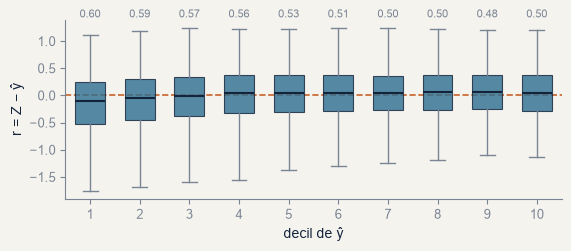

In [59]:
#### Residuo por decil de f (OOF): la forma que impone el mapeo
d_oof = resid_hs.loc[resid_hs.periodo == "oof", ["f", "r"]].dropna()
d_oof["decil"] = np.digitize(d_oof["f"], bordes) + 1
datos = [d_oof.loc[d_oof.decil == k, "r"].values for k in deciles]

fig, ax = plt.subplots(figsize=(5.6, 2.4), constrained_layout=True)
bp = ax.boxplot(datos, widths=0.6, showfliers=False, patch_artist=True, whis=(1, 99),
                medianprops=dict(color=TINTA, lw=1.5), whiskerprops=dict(color=GRIS),
                capprops=dict(color=GRIS), boxprops=dict(edgecolor=TINTA, lw=0.8))
for caja in bp["boxes"]:
    caja.set_facecolor(AZUL); caja.set_alpha(0.8)
ax.axhline(0, color=NARANJA, lw=1.2, ls="--", zorder=0)
ytop = ax.get_ylim()[1]
for k, v in zip(deciles, datos):
    ax.text(k, ytop, f"{v.std():.2f}", ha="center", va="bottom", fontsize=8, color=GRIS)
ax.set(xlabel="decil de ŷ", ylabel="r = Z − ŷ", xticks=deciles)
fig.savefig("figuras/05B_ruido_residuo_deciles.png", dpi=200)
plt.show()

In [60]:
#### Diagnóstico (26/11): dentro del decil 10, ¿depende r de f? → la media cae de +0.07 a −0.02 en el 2 % más alto,
#### pero clases más finas arriba (q95, q98) no arreglaron el nº de temporales y acortaron las duraciones (0.90): se quedan 10 deciles
top = d_oof[d_oof.decil == 10].copy()
top["sub"] = pd.qcut(top["f"], 5, labels=["q90–92", "q92–94", "q94–96", "q96–98", "q98–100"])
print(top.groupby("sub")["r"].agg(["mean", "std", "count"]).round(3))

          mean    std  count
sub                         
q90–92   0.062  0.486   5435
q92–94   0.091  0.491   5434
q94–96   0.061  0.518   5435
q96–98   0.049  0.508   5434
q98–100 -0.024  0.480   5435


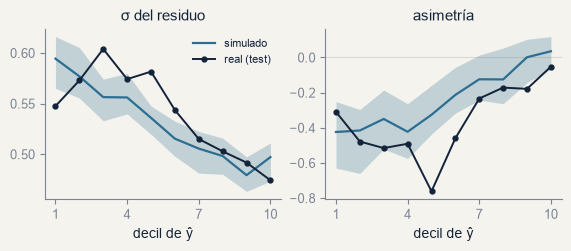

In [61]:
#### σ y asimetría del residuo por decil de f: real (test) vs simulado
d = pd.DataFrame({"f": f_sim, "r_real": resid_hs["r"].reindex(f_sim.index)}).loc[TEST[0]:TEST[1]]
d["decil"] = np.digitize(d["f"], bordes) + 1
g = r_sims.loc[d.index].groupby(d["decil"])

sd_real, sk_real = d.groupby("decil")["r_real"].std(), d.groupby("decil")["r_real"].apply(lambda x: skew(x.dropna()))
sd_sim, sk_sim = g.std(), g.agg(lambda x: skew(x))                     # (decil, sim)

fig, axs = plt.subplots(1, 2, figsize=(5.6, 2.4), constrained_layout=True, sharex=True)
for ax, real, sim, lab in [(axs[0], sd_real, sd_sim, "σ del residuo"), (axs[1], sk_real, sk_sim, "asimetría")]:
    p5, p50, p95 = np.percentile(sim.values, [5, 50, 95], axis=1)
    ax.fill_between(sim.index, p5, p95, color=AZUL, alpha=0.25, lw=0)
    ax.plot(sim.index, p50, color=AZUL, lw=1.6, label="simulado")
    ax.plot(real.index, real.values, "o-", color=TINTA, lw=1.4, ms=3.5, label="real (test)")
    ax.set(title=lab, xlabel="decil de ŷ", xticks=[1, 4, 7, 10])
axs[1].axhline(0, color="#DDD8CE", lw=0.8, zorder=0)
axs[0].legend(frameon=False, fontsize=8)
fig.savefig("figuras/05B_ruido_sigma_asimetria.png", dpi=200)
plt.show()

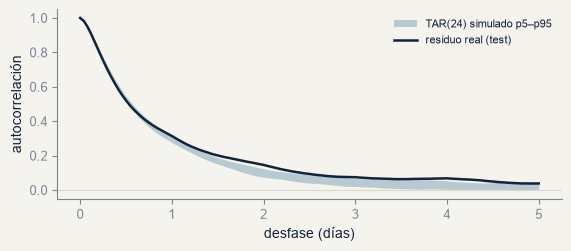

In [62]:
#### Persistencia del residuo: real (test) vs TAR simulado
lags = np.arange(0, 121)                                # 5 días
acf_real = acf_h(resid_hs.loc[TEST[0]:TEST[1], "r"], lags)
acf_sim = np.array([acf_h(r_sims[c].loc[TEST[0]:TEST[1]], lags) for c in r_sims.columns])
p5, p95 = np.percentile(acf_sim, [5, 95], axis=0)

fig, ax = plt.subplots(figsize=(5.6, 2.4), constrained_layout=True)
ax.fill_between(lags / 24, p5, p95, color=AZUL, alpha=0.3, lw=0, label="TAR(24) simulado p5–p95")
ax.plot(lags / 24, acf_real, color=TINTA, lw=1.8, label="residuo real (test)")
ax.axhline(0, color="#DDD8CE", lw=0.8)
ax.set(xlabel="desfase (días)", ylabel="autocorrelación")
ax.legend(frameon=False, fontsize=8)
fig.savefig("figuras/05B_ruido_acf.png", dpi=200)
plt.show()

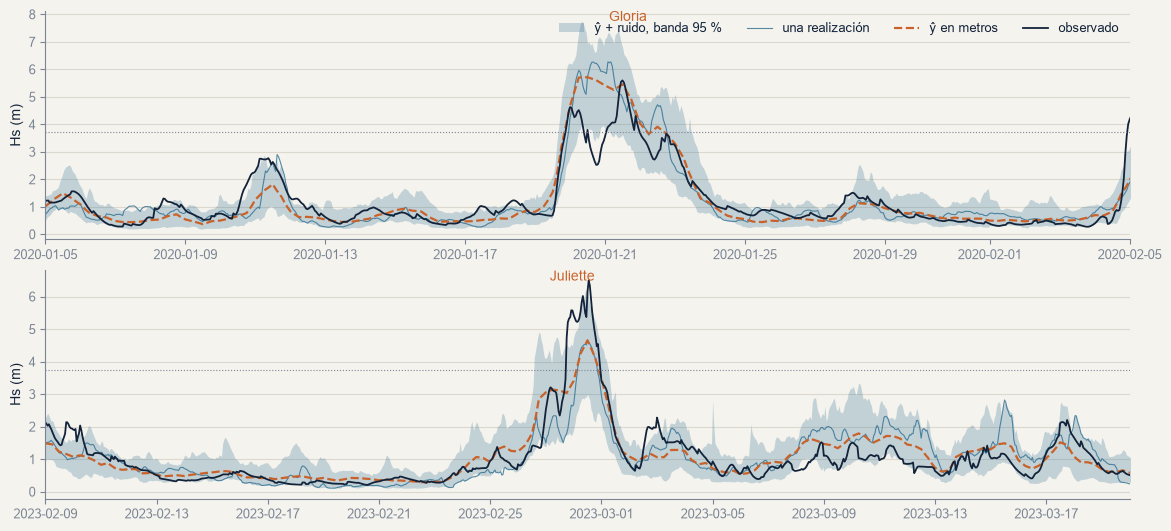

In [63]:
#### Hindcast en dos temporales del test: Hs observada vs banda de las realizaciones
ventanas = [("2020-01-05", "2020-02-05", ("Gloria", "2020-01-21")),
            ("2023-02-09", "2023-03-20", ("Juliette", "2023-02-27"))]

fig, axs = plt.subplots(len(ventanas), 1, figsize=(11.6, 2.6 * len(ventanas)), constrained_layout=True)
for ax, (t0, t1, (nombre, fecha)) in zip(axs, ventanas):
    w = hs_sims.loc[t0:t1]
    ax.fill_between(w.index, w.quantile(0.025, axis=1), w.quantile(0.975, axis=1), color=AZUL, alpha=0.25, lw=0,
                    label="ŷ + ruido, banda 95 %")
    ax.plot(w.iloc[:, 0], color=AZUL, lw=0.8, alpha=0.8, label="una realización")
    ax.plot(hs_f.loc[t0:t1], color=NARANJA, lw=1.6, ls="--", label="ŷ en metros")
    ax.plot(hs_obs_h.loc[t0:t1], color=TINTA, lw=1.3, label="observado")
    ax.axhline(U99, color=GRIS, lw=0.8, ls=":")
    ax.text(pd.Timestamp(fecha), ax.get_ylim()[1], f" {nombre}", color=NARANJA, fontsize=10, va="top")
    ax.set(ylabel="Hs (m)", xlim=(pd.Timestamp(t0), pd.Timestamp(t1)))
    ax.grid(axis="y", color="#DDD8CE", lw=0.8); ax.set_axisbelow(True)
axs[0].legend(frameon=False, loc="upper right", ncol=4, fontsize=9)
fig.savefig("figuras/05B_ruido_temporales_hindcast.png", dpi=200)
plt.show()

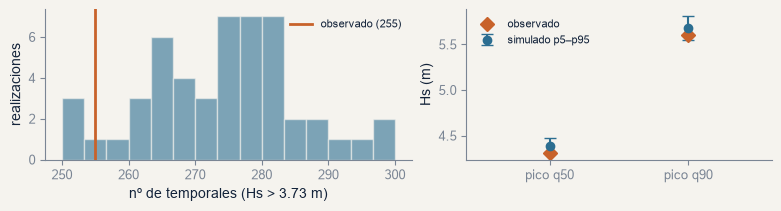

In [64]:
#### Nº de temporales y tamaño de los picos (hindcast completo)
p_obs = hs_obs_h.loc[picos_temporal(hs_obs_h)].values
p_sim = [hs_sims[c].loc[picos_temporal(hs_sims[c].where(hay_obs))].values for c in hs_sims.columns]
n_sim = [len(p) for p in p_sim]

fig, axs = plt.subplots(1, 2, figsize=(7.7, 2.0), constrained_layout=True, gridspec_kw={"width_ratios": [1.2, 1]})
axs[0].hist(n_sim, bins=15, color=AZUL, alpha=0.6, edgecolor=FONDO)
axs[0].axvline(len(p_obs), color=NARANJA, lw=2, label=f"observado ({len(p_obs)})")
axs[0].set(xlabel=f"nº de temporales (Hs > {U99:.2f} m)", ylabel="realizaciones")
axs[0].legend(frameon=False, fontsize=8)

for j, q in enumerate([0.5, 0.9]):
    qs = np.array([np.quantile(p, q) for p in p_sim])
    p5, p50, p95 = np.percentile(qs, [5, 50, 95])
    axs[1].errorbar(j, p50, yerr=[[p50 - p5], [p95 - p50]], fmt="o", color=AZUL, capsize=4, lw=1.5,
                    label="simulado p5–p95" if j == 0 else None)
    axs[1].plot(j, np.quantile(p_obs, q), "D", color=NARANJA, ms=7, label="observado" if j == 0 else None)
axs[1].set_xticks([0, 1], ["pico q50", "pico q90"])
axs[1].set(ylabel="Hs (m)", xlim=(-0.6, 1.6))
axs[1].legend(frameon=False, fontsize=8)
fig.savefig("figuras/05B_ruido_temporales_n.png", dpi=200)
plt.show()

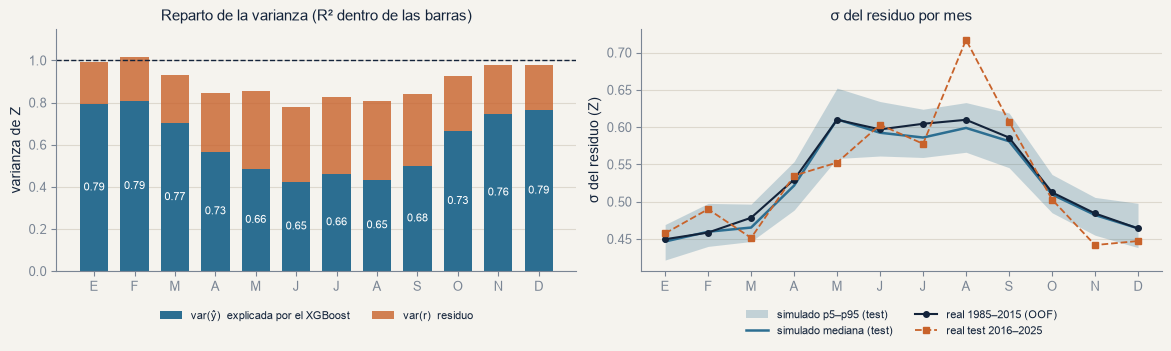

In [65]:
#### Estacionalidad del residuo: reparto de la varianza de Z y σ(r) por mes
meses = np.arange(1, 13)
etq = ["E", "F", "M", "A", "M", "J", "J", "A", "S", "O", "N", "D"]

oof = resid_hs.loc[resid_hs.periodo == "oof", ["z", "f", "r"]].dropna()
g = oof.groupby(oof.index.month)
var_f, var_r = g["f"].var(), g["r"].var()
r2 = g.apply(lambda x: x["z"].corr(x["f"]) ** 2)

sd_oof = g["r"].std()
sd_test = resid_hs.loc[resid_hs.periodo == "test", "r"].groupby(lambda t: t.month).std()
r_test = r_sims.loc[TEST[0]:TEST[1]]
sd_sim = r_test.groupby(r_test.index.month).std()                    # (mes, realización)
p5, p50, p95 = np.percentile(sd_sim.values, [5, 50, 95], axis=1)

fig, axs = plt.subplots(1, 2, figsize=(11.6, 3.4), constrained_layout=True)
axs[0].bar(meses, var_f, color=AZUL, width=0.7, label="var(ŷ)  explicada por el XGBoost")
axs[0].bar(meses, var_r, bottom=var_f, color=NARANJA, alpha=0.8, width=0.7, label="var(r)  residuo")
axs[0].axhline(1, color=TINTA, lw=1, ls="--")
for m in meses:
    axs[0].text(m, var_f[m] / 2, f"{r2[m]:.2f}", ha="center", va="center", fontsize=8, color="white")
axs[0].set(xticks=meses, xticklabels=etq, ylim=(0, 1.15), ylabel="varianza de Z",
           title="Reparto de la varianza (R² dentro de las barras)")
axs[0].legend(frameon=False, fontsize=8, loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.12))

axs[1].fill_between(meses, p5, p95, color=AZUL, alpha=0.25, lw=0, label="simulado p5–p95 (test)")
axs[1].plot(meses, p50, color=AZUL, lw=1.8, label="simulado mediana (test)")
axs[1].plot(meses, sd_oof.reindex(meses), "o-", color=TINTA, lw=1.5, ms=4, label="real 1985–2015 (OOF)")
axs[1].plot(meses, sd_test.reindex(meses), "s--", color=NARANJA, lw=1.3, ms=4, label="real test 2016–2025")
axs[1].set(xticks=meses, xticklabels=etq, ylabel="σ del residuo (Z)", title="σ del residuo por mes")
axs[1].legend(frameon=False, fontsize=8, loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.12))
for ax in axs:
    ax.grid(axis="y", color="#DDD8CE", lw=0.8); ax.set_axisbelow(True)
fig.savefig("figuras/05B_ruido_estacionalidad.png", dpi=200)
plt.show()

Spearman r: real 0.508 | sim p50 0.559


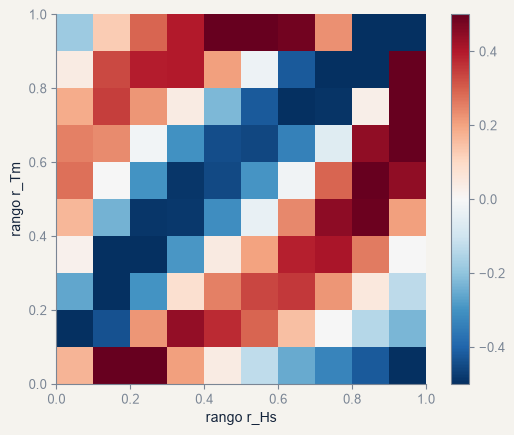

In [67]:
dens = lambda U, V: np.histogram2d(U, V, bins=10, range=[[0, 1], [0, 1]])[0] / len(U) * 100
#### Cópula de los residuos (r_Hs, r_Tm): real (OOF+test) vs ruido simulado del 05B
r_real = pd.concat({"h": resid_hs["r"], "t": resid_tm["r"]}, axis=1).dropna()
t_ok = r_real.index.intersection(r_sims.index)
rk = lambda x: x.rank() / (len(x) + 1)
d_obs_r = dens(rk(r_real.loc[t_ok, "h"]).values, rk(r_real.loc[t_ok, "t"]).values)
d_sim_r = np.stack([dens(rk(r_sims.loc[t_ok, c]).values, rk(rtm_sims.loc[t_ok, c]).values) for c in r_sims.columns])
print(f"Spearman r: real {r_real.loc[t_ok].corr('spearman').iloc[0, 1]:.3f} | sim p50 "
      f"{np.median([r_sims.loc[t_ok, c].corr(rtm_sims.loc[t_ok, c], method='spearman') for c in r_sims.columns]):.3f}")
plt.imshow((d_obs_r - d_sim_r.mean(0)).T, origin="lower", extent=[0, 1, 0, 1], cmap="RdBu_r", vmin=-0.5, vmax=0.5)
plt.colorbar(); plt.xlabel("rango r_Hs"); plt.ylabel("rango r_Tm"); plt.show()

In [68]:
x = ruido_tar(f_sim, np.random.default_rng(0))
print(pd.Series(x[:, 0]).corr(pd.Series(x[:, 1]), method="spearman"))

0.5631023869108325
